# Визуализация данных

В этой тетрадке мы поучимся рисовать графики. Общий алгоритм выбора библиотеки:
1. "Мне только посмотреть" $-$ функция `plot()` прямо внутри pandas
1. Донастроить и сделать покрасивее $-$ [matplotlib](https://matplotlib.org/)
1. Редкие графики (heatmap, pairplot) + базово красиво $-$ [seaborn](https://seaborn.pydata.org/)
1. Интерактивный график $-$ [plotly](https://plotly.com/python/)
1. Очень Красивый график $-$ уже не питон (см. презентацию)


! Если вы совсем не знакомы с базовыми типами графиков (вопрос-проверка: что такое барчарт и чем он отличается от гистограммы), желательно изучить начало [презентации](https://docs.google.com/presentation/d/1ZsLi-N3hfpowzXhxvOfwj-sx6es-Qnr67bQXqApZvpA/edit?usp=sharing).

## Данные

In [ ]:
!pip install wget --q # пакет-аналог !wget
!pip install plotly --q

  Preparing metadata (setup.py) ... done


In [ ]:
import wget
import pandas as pd
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Сегодня мы строим графики на примере хрестоматийного датасета "Титаник".

In [ ]:
wget.download('https://raw.githubusercontent.com/hse-ling-python/seminars/refs/heads/master/visualization/data/data_titanic.csv')
df_titanic = pd.read_csv("data_titanic.csv", sep=';')

In [ ]:
df_titanic.sample(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
282,283,0,3,de Pelsmaeker; Mr. Alfons,male,16.0,0,0,345778,9.5,NaN,S
834,835,0,3,Allum; Mr. Owen George,male,18.0,0,0,2223,8.3,NaN,S
270,271,0,1,Cairns; Mr. Alexander,male,NaN,0,0,113798,31.0,NaN,S


## 1. Pandas

Чаще всего нужно построить частотную/сводную таблицу. Посмотрим, сколько было пассажиров каждого класса:

<Axes: ylabel='count'>

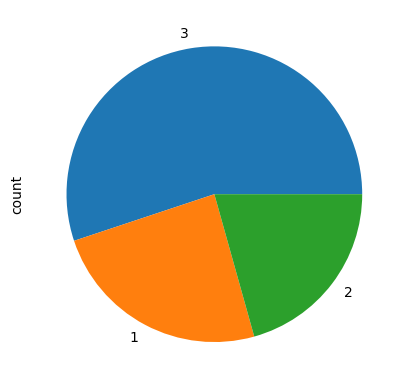

In [ ]:
df_titanic['Pclass'].value_counts().plot(kind='pie')

Теперь со сводной таблицей: посчитаем, как выживаемость зависит от пола и быстренько визуализируем:

In [ ]:
# unstack трансформирует таблицу в широкий формат
titanic_groupby = df_titanic.groupby(['Survived', 'Sex']).size().unstack()
titanic_groupby

Sex,female,male,unknown
Survived,,,
0,80,466,3
1,232,108,2


<Axes: xlabel='Survived'>

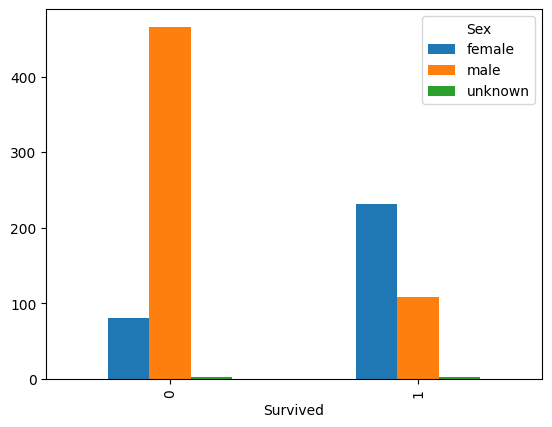

In [ ]:
titanic_groupby.plot(kind='bar')

Очередное доказательство, что мужчины живут меньше.

В наших силах украсить график даже здесь:

<Axes: title={'center': 'Погибшие и выжившие по полу'}, ylabel='Количество пассажиров'>

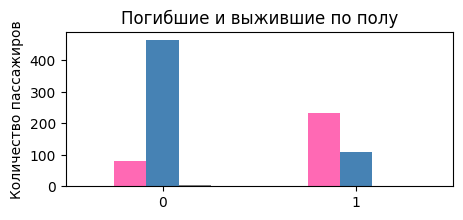

In [ ]:
titanic_groupby.plot(
    kind='bar',
    title='Погибшие и выжившие по полу',
    ylabel='Количество пассажиров',
    xlabel='',
    legend=False, # без легенды (таблички с цветами)
    rot=0, # горизонтальные подписи
    color=['hotpink', 'steelblue', 'grey'],
    figsize=(5, 2) #размер
    )

Через `pd.plot` можно настроить довольно много (выше лишь основные параметры), но гораздо больше можно сделать в библиотеке matplotlib.

## Matplotlib

In [ ]:
import matplotlib.pyplot as plt

На самом деле в прошлом разделе мы использовали библиотеку matplotlib (точнее её использовал пандас). И seaborn из следующего раздела тоже основан именно на matplotlib.

У этой библиотеки есть огромное количество [гайдов](https://matplotlib.org/stable/users/explain/quick_start.html#quick-start), [шпаргалок](https://matplotlib.org/cheatsheets/) и [примеров графиков](https://matplotlib.org/stable/plot_types/index.html).

Если мы хотим нарисовать график с помощью matplotlib, мы можем последовательно вызывать внутри ячейки нужные методы этой библиотеки. Простой пример:

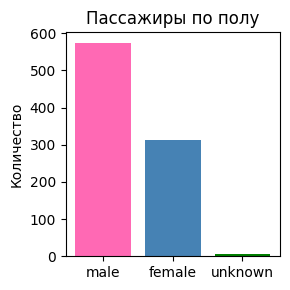

In [ ]:
counts = df_titanic['Sex'].value_counts()

plt.figure(figsize=(3, 3))
plt.bar(counts.index, counts.values, color=['hotpink', 'steelblue', 'green'])
plt.title('Пассажиры по полу')
plt.ylabel('Количество')
plt.tight_layout() # автоматическая подгонка, чтобы не обрезать подписи и т.д.
plt.show() # выводим финальный график

(Доступные цвета можно найти [здесь](https://matplotlib.org/stable/gallery/color/named_colors.html).)

> Минутка продвинутой душноты: Существует также метод рисовки через `fig, ax = plt.subplots()` (создание холста и графиков внутри), и сами разработчики [в примерах используют именно его](https://matplotlib.org/stable/plot_types/basic/bar.html). Он лучше совместим с рисовкой нескольких графиков в одной ячейке, более сложной кастомизацией, доработкой графиков из других библиотек, использующих matplotlib внутри (например, можно сохранить `df.plot()` в переменную и дополнить его командами из plt). Но в рамках одиночных несложных графиков вполне допустимо писать и так, как в этой тетрадке.



Для чего тогда может пригодиться сложный matplotlib, если есть `df.plot()`?

- Смешивать данные из разных источников на одном графике (или рисовать график по данным из списков)
- Комбинировать типы графиков (линия поверх столбчатой диаграммы)
- Добавлять аннотации и стрелки (выделить объект на графике)
- Производить точечную настройку (цвет отдельной точки/столбца, переделать легенду)

По сути matplotlib $-$ профессиональный фотоаппарат, df.plot() $-$ камера телефона с хорошими, но автоматическими настройками (да, эту глубочайшую метафору создала нейросеть, но написала я её своей кринжовой рукой).

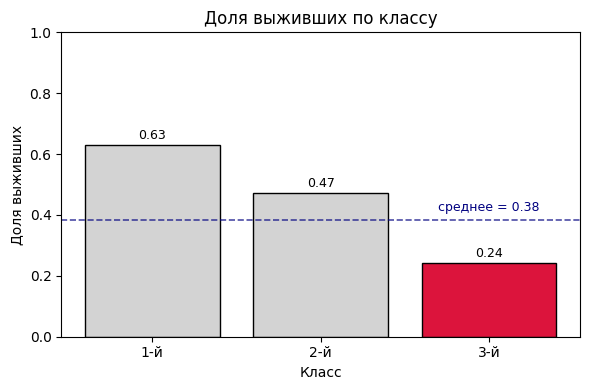

In [ ]:
survival = df_titanic.groupby('Pclass')['Survived'].mean()
highlight = 3 # ← что выделяем

# 1. цвета
colors = ['crimson' if c == highlight else 'lightgrey'
          for c in survival.index]

# 2. фигура и столбцы
plt.figure(figsize=(6, 4))
bars = plt.bar(survival.index, survival.values,
               color=colors, edgecolor='black')

# 3. линия-ориентир + подпись
overall = df_titanic['Survived'].mean()
plt.axhline(overall, color='navy', linestyle='--', linewidth=1.2, alpha=0.7)
plt.text(3, overall + 0.02, f'среднее = {overall:.2f}',
         color='navy', fontsize=9, va='bottom', ha='center')

# 4. значения над столбцами
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.02,
             f'{h:.2f}', ha='center', fontsize=9)

# 5. оформление
plt.title(f'Доля выживших по классу')
plt.xlabel('Класс')
plt.ylabel('Доля выживших')
plt.xticks([1, 2, 3], ['1-й', '2-й', '3-й'], rotation=0)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

А вот так можно делать сетку из нескольких графиков:

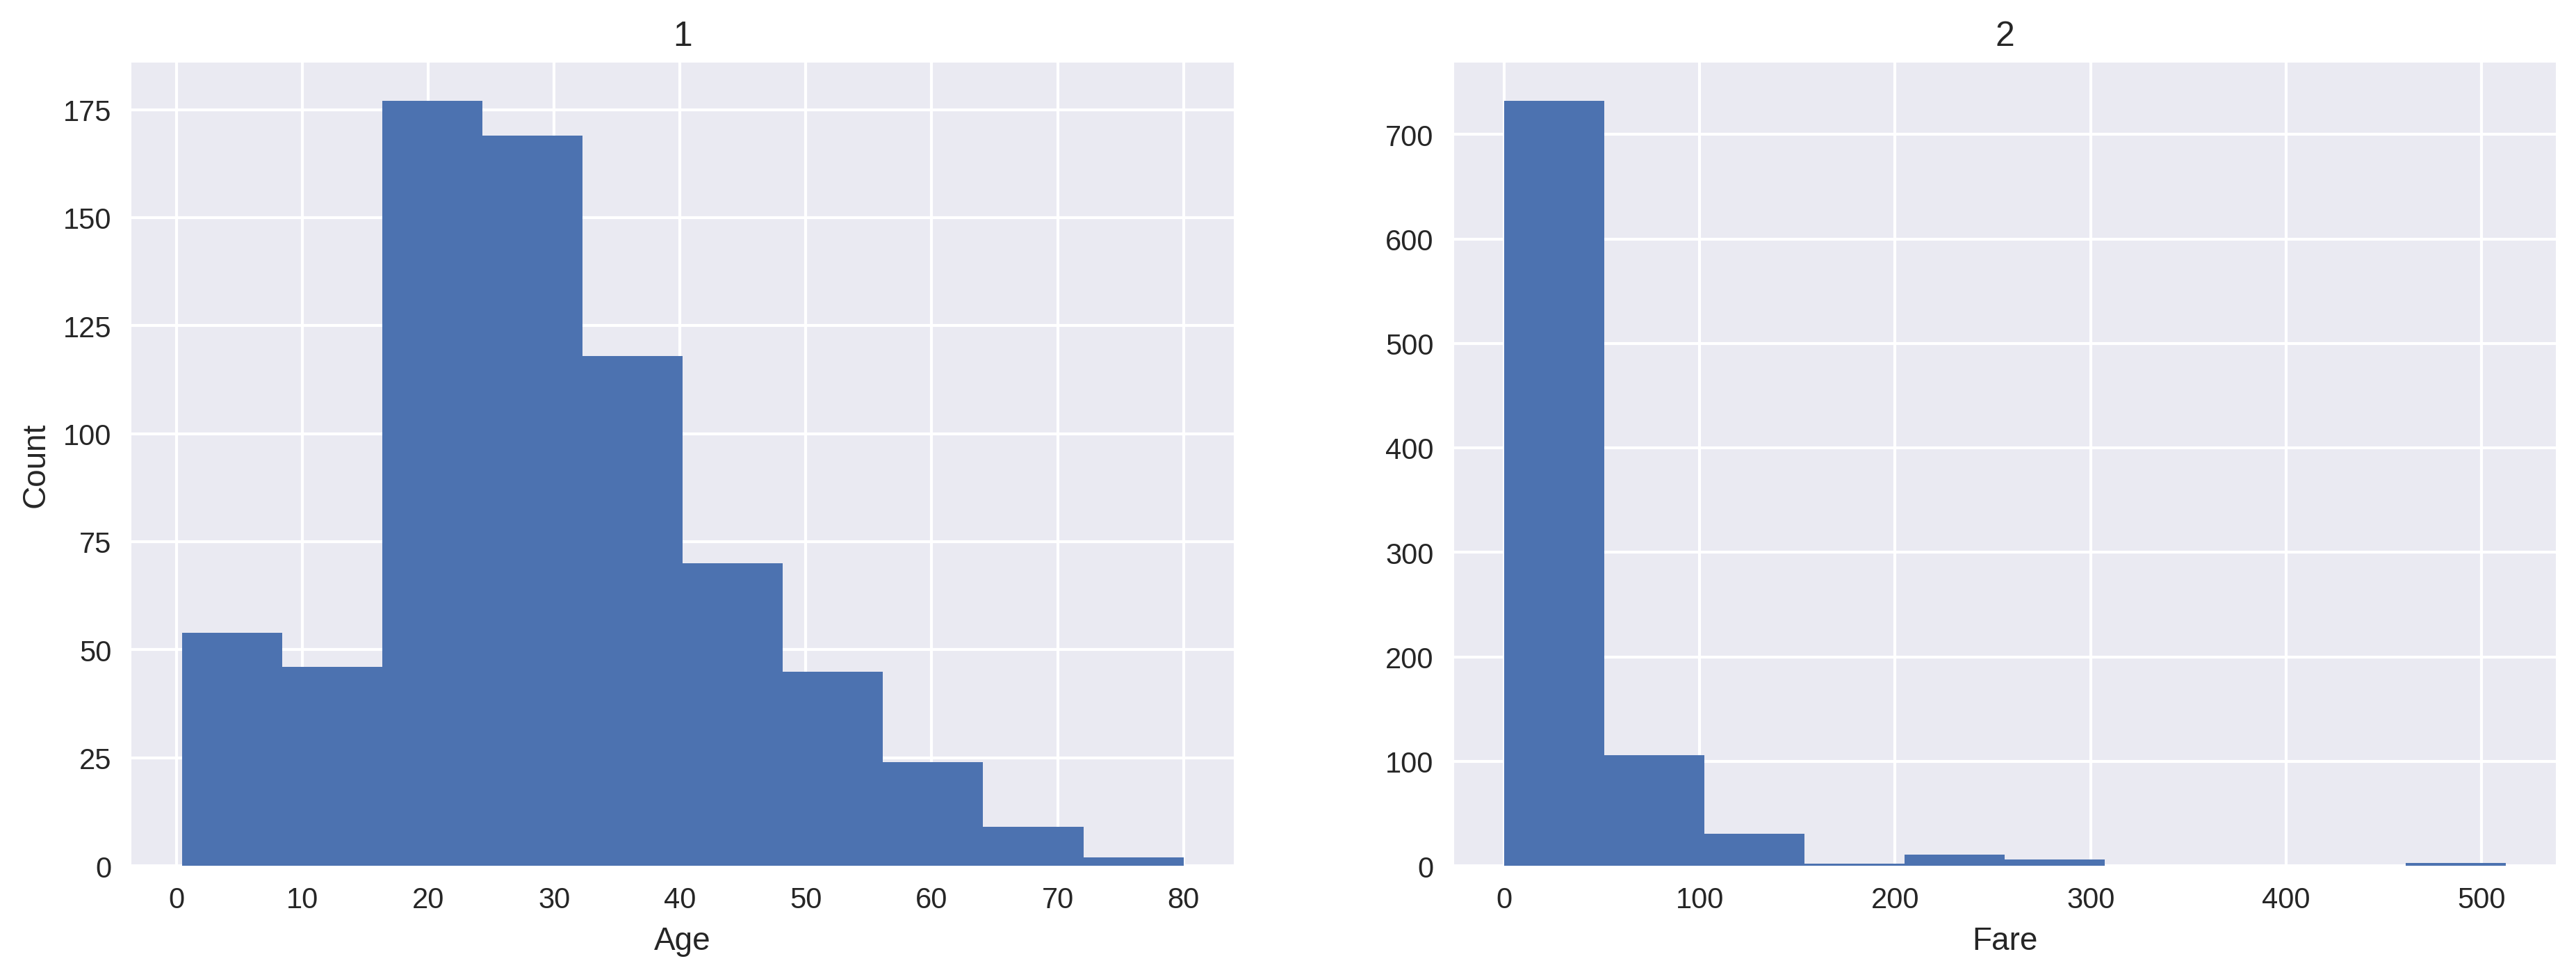

In [ ]:
plt.style.use("seaborn-v0_8") # использовать тему вместо белого фона

plt.figure(figsize=(15, 5), dpi=300)

plt.subplot(1, 2, 1)
plt.title("1")
plt.hist(df_titanic["Age"])
plt.ylabel("Count")
plt.xlabel("Age")

plt.subplot(1, 2, 2)
plt.title("2")
plt.hist(df_titanic["Fare"])
plt.xlabel("Fare")

plt.show()

## Seaborn

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

По сути seaborn по умолчанию красивый, но чтобы поменять или добавить некоторые штуки (размер графика, стрелочки-аннотации и т.д.), удобно использовать их одновременно:

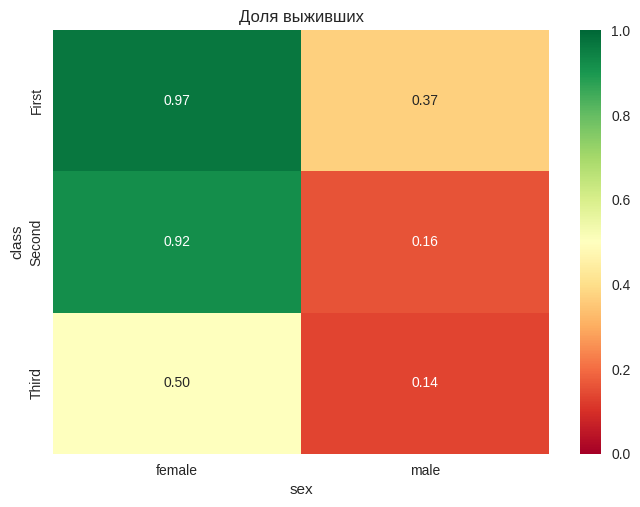

In [ ]:
df = sns.load_dataset('titanic') # seaborn даже хранит датасеты-примеры
grouped = df.groupby(['class', 'sex'])['survived'].mean().unstack()

ax = sns.heatmap(grouped,
                 annot=True,
                 fmt='.2f',
                 cmap='RdYlGn',
                 vmin=0, vmax=1)

ax.set_title('Доля выживших');

И ещё seaborn может очень быстро и красиво нарисовать вот такие штуки:

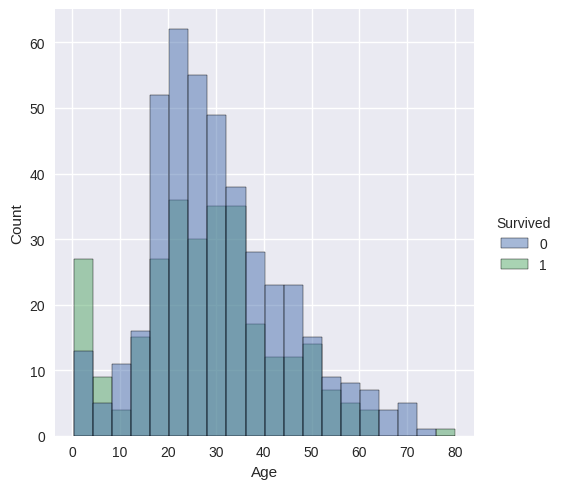

In [ ]:
# распределение с группировкой
sns.displot(df_titanic, x="Age", hue="Survived");

Pairplot: по диагонали $-$ распределение каждой числовой переменной с учётом целевой переменной (в примере нас интересует, выжил пассажир или нет, и два цвета обозначают распределения для одного и другого значения). В остальных ячейках $-$ scatter plot каждой пары числовых переменных с учётом целевой переменной.

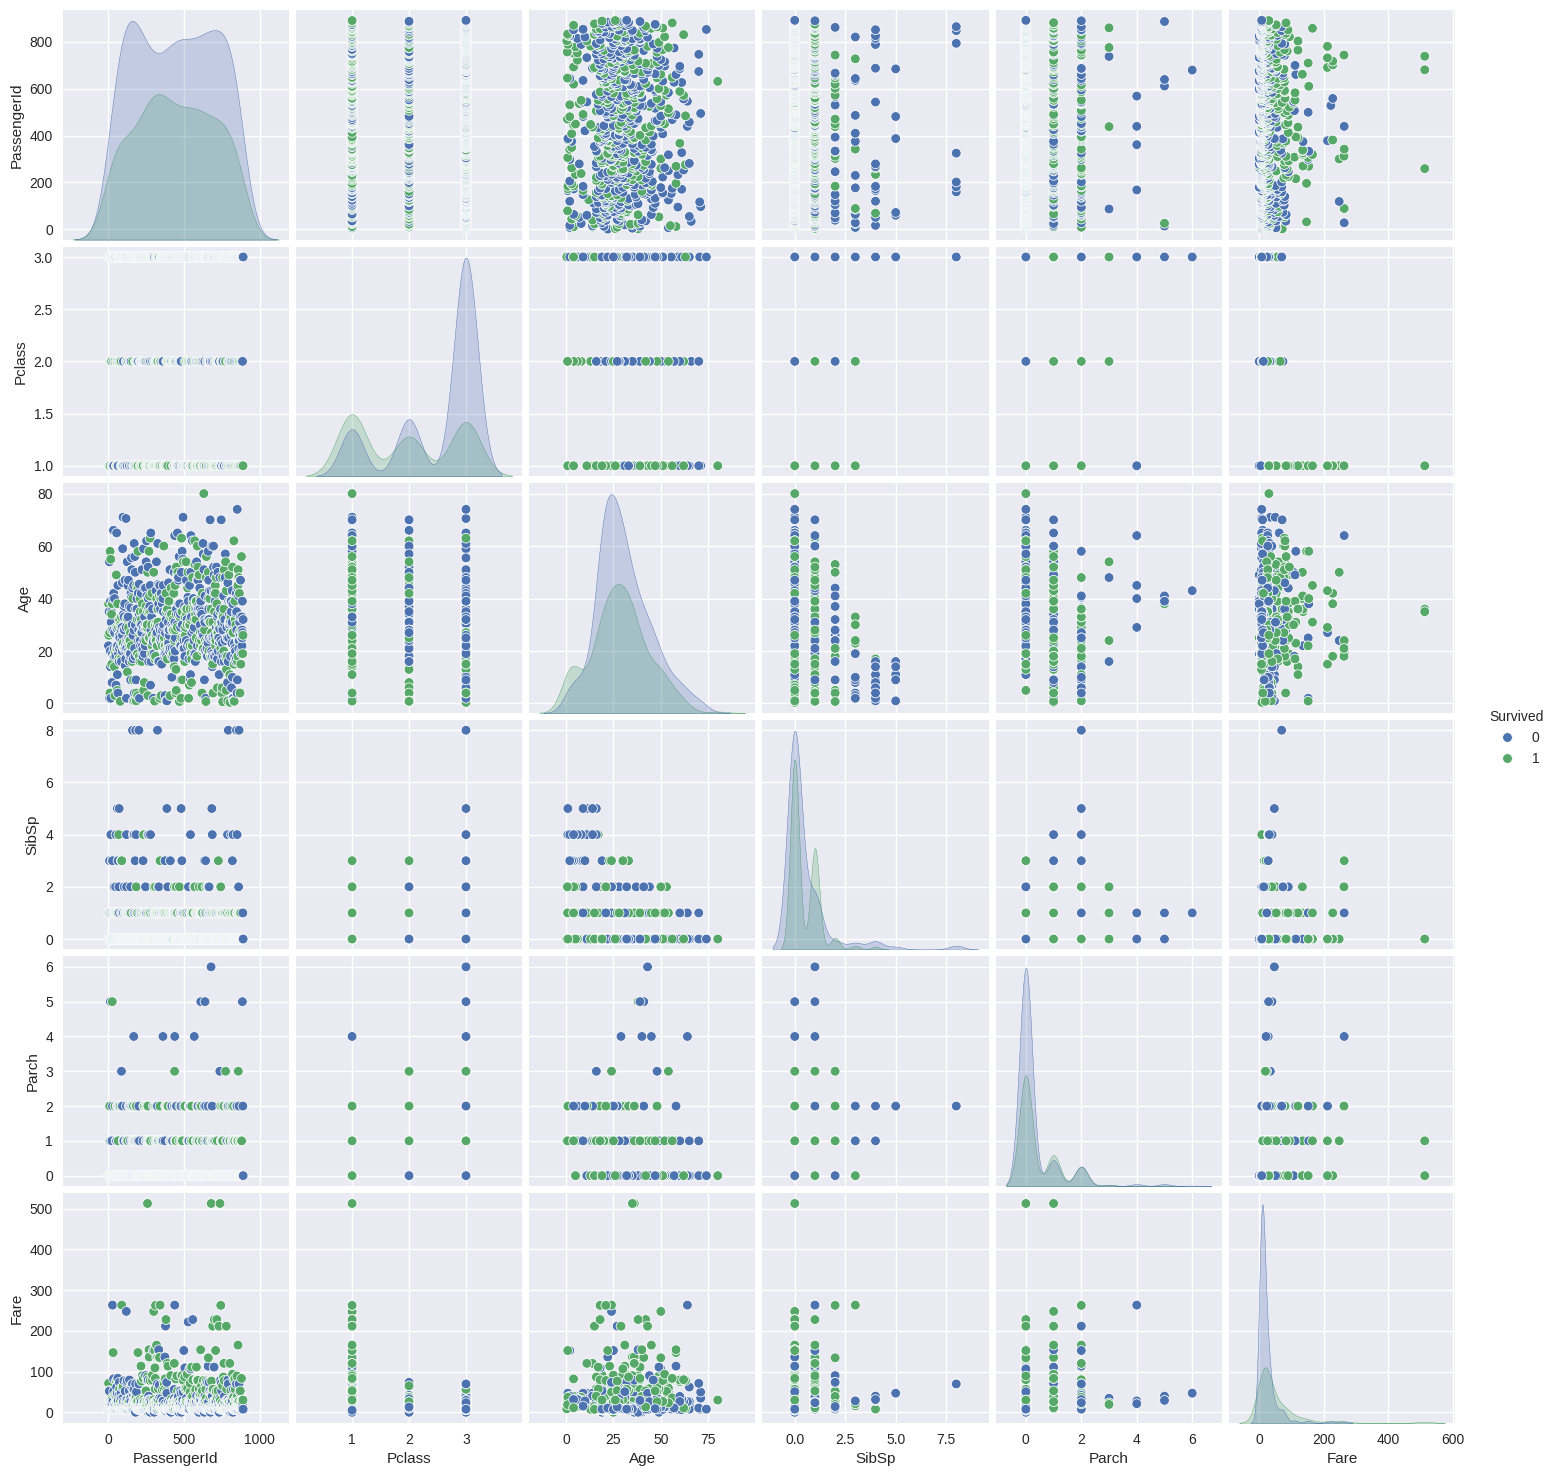

In [ ]:
sns.pairplot(df_titanic, hue="Survived");

## Практика

Для тренировки возьмём датасет о прокатных удостоверениях фильмов:

In [ ]:
!pip install wget --q

In [ ]:
import wget
import pandas as pd

In [ ]:
wget.download('https://github.com/hse-ling-python/seminars/raw/refs/heads/master/visualization/data/data_cinema.zip')

'data_cinema.zip'

In [ ]:
df_cinema = pd.read_csv("data_cinema.zip", parse_dates=[3, 4, 37, 44, 46, 47])
df_cinema.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 48 columns):
 #   Column                                                 Non-Null Count  Dtype                    
---  ------                                                 --------------  -----                    
 0   Название фильма                                        11000 non-null  object                   
 1   Hаименование на иностранном языке                      5369 non-null   object                   
 2   Номер удостоверения                                    11000 non-null  object                   
 3   Дата регистрации удостоверения                         11000 non-null  datetime64[ns, UTC]      
 4   Дата начала показа фильма                              10046 non-null  datetime64[ns, UTC]      
 5   Примечание                                             2878 non-null   object                   
 6   Идентификатор записи реестра                           11000 non-null 

Задания предлагают разные возможности для тренировки (и подсвечивают основные доп. опции для каждого графика), но не должны быть выполнены от начала и до конца, базово на курсе мы хотим от вас умения построить обычный аккуратный график.

### Столбчатая диаграмма

Лёгкая версия: постройте барчарт по топу самых популярных жанров (столбец "Вид фильма"). Подумайте, как сделать, чтобы названия жанров нормально читались на графике.

(по возможности приведите данные в опрятный вид)


Версия посложнее: постройте барчарт по количеству фильмов, вышедших в каждый день недели.

1. Данные
- создайте столбец с днём недели (в datetime встроена опция определить день недели, погуглите!)
2. Визуализация
- версия-минимум: подпишите график, оси, названия дней недели, убедитесь, что они в правильном порядке
- дополнительные варианты
  - выделите выходные другим цветом
  - добавьте линию-среднее
  - поделить фильмы на старые и новые, посчитать долю каждого дня недели по категориям, сделать барчарт с группами столбцов (как выше в тетрадке)
  - придумать своё безумное усложнение

### Диаграмма рассеяния (aka точечная диаграмма aka scatter plot)

Постройте график, осями которого будут длительность фильма и метраж пленки, а точками $-$ отдельные картины (столбцы "Метраж (для фильмов на кинопленке)", "Продолжительность демонстрации, часы", "Продолжительность демонстрации, минуты")

(можно взять только выборку из датасета в 100-200 фильмов, потому что диаграмма на 11 тысяч точек может весьма долго строиться и сильно нагружать память)

1. Данные
- создайте новый столбец с общей длительностью фильма в минутах
- приведите оба необходимых столбца к числовому формату
2. Визуализация
- версия-минимум: подпишите график и оси
- дополнительные варианты
  - настройте прозрачность точек, чтобы они не так сильно слеплялись в одно пятно
  - выделите цветом особо длинные фильмы, а маркером (фигуркой) фильмы конкретного жанра
  - добавьте столбец со случайными значениями от 1 до 3 и сделайте размер точки пропорциональным этому столбцу (поскольку настоящих подходящих столбцов тут нет...)



### Линейный график

Постройте линейный график, показывающий количество фильмов в каждый год. (столбец "Год производства")

1. Данные
- легкая версия: удалите неформатные значения
- сложная версия: обработайте неформатные значения (придумайте, как это логично было бы сделать и как это реализовать)
2. Визуализация
- версия-минимум: подпишите график и оси
- дополнительные варианты
  - включите тему
  - подберите цвет линии
  - добавьте линию со средним числом фильмов в год (если бы это был настоящий график, это было бы абсолютно неуместно, но мы тренируемся), подпишите её
  - добавьте аннотацию: укажите на наибольшее значение на графике стрелкой и подпишите


## Дополнительно

### Plotly

In [ ]:
import plotly.express as px

In [ ]:
import seaborn as sns
df = sns.load_dataset('titanic')

Plotly важно упомянуть прежде всего из-за встроенной интерактивности. Если вам нужно "потыкать в график" или встроить такой график на сайт, то это самый быстрый инструмент (в питоне) для создания подобной визуализации. Однако помните, что подобная интерактивность часто избыточна.

In [ ]:
grouped = (df.groupby(['class', 'sex'], observed=True)['survived']
             .mean()
             .reset_index())

fig = px.bar(grouped,
             x='class',
             y='survived',
             color='sex',
             barmode='group',
             title='Доля выживших по классу и полу',
             labels={'survived': 'Доля выживших',
                     'class': 'Класс',
                     'sex': 'Пол'})

fig.show()

### Wordcloud

Для отрисовки в питоне облака слов можно использовать библиотеку [wordcloud](https://amueller.github.io/word_cloud/). Однако этот тип визуализации несёт не так много смысла (исследователю часто полезнее посмотреть на частотную таблицу) и одновременно с этим давно устарел эстетически.

### Ресурсы

1. [Презентация](https://docs.google.com/presentation/d/1ZsLi-N3hfpowzXhxvOfwj-sx6es-Qnr67bQXqApZvpA/edit?usp=sharing)!!
1. Туториалы от [matplotlib](https://matplotlib.org/stable/tutorials/) и [seaborn](seaborn.pydata.org/tutorial.html)
1. [Галерея](matplotlib.org/stable/gallery/) matplotlib (если нужно вдохновение, что именно вы хотите на графике)
1. Бесплатный [курс](https://app.datacamp.com/learn/skill-tracks/data-visualization-with-python#1) по визуализации данных в питоне